<a href="https://colab.research.google.com/github/Zain62543/Zain62543/blob/main/RandomForest_Example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Random Forest Classification with Python 🌳

**Author:** Zain Ud Din

## Objective
Train a Random Forest classifier on the Iris dataset and evaluate its predictions. This notebook covers data exploration, model training, evaluation, feature importance, and prediction for a new flower.

## 1. Import libraries

The Iris dataset is included with Scikit-learn, so no separate dataset download is needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 2. Load and explore the dataset

In [2]:
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

df = X.copy()
df["species"] = y.map(dict(enumerate(iris.target_names)))

display(df.head())
print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["species"].value_counts())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset shape: (150, 5)

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 3. Visualize the data

This scatter plot compares petal length and petal width for the three Iris species.

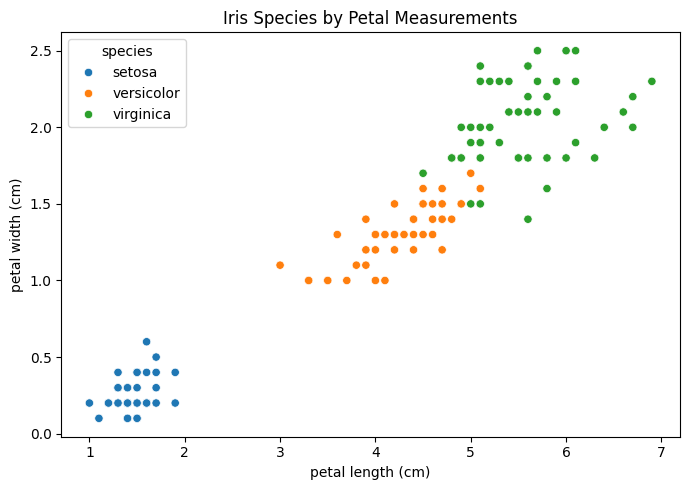

In [3]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species"
)
plt.title("Iris Species by Petal Measurements")
plt.tight_layout()
plt.show()

## 4. Split the dataset

We use 80% of the samples for training and 20% for testing. Stratification keeps the class proportions similar in both sets.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


## 5. Train the Random Forest model

`n_estimators=100` tells the model to build 100 decision trees. `random_state=42` helps make the result reproducible.

In [5]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
print("Model training completed!")

Model training completed!


## 6. Evaluate the model

Accuracy is the proportion of correct predictions. The classification report also shows precision, recall, and F1-score for each class.

In [6]:
y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))

Accuracy: 0.900

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



## 7. Confusion matrix

Rows represent the actual classes and columns represent the predicted classes.

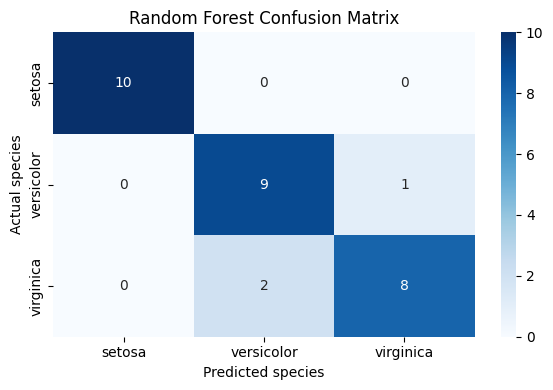

In [7]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.xlabel("Predicted species")
plt.ylabel("Actual species")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Feature importance

Feature importance estimates how useful each input feature was to this fitted forest. It should be interpreted as a model-specific measure, not proof of cause and effect.

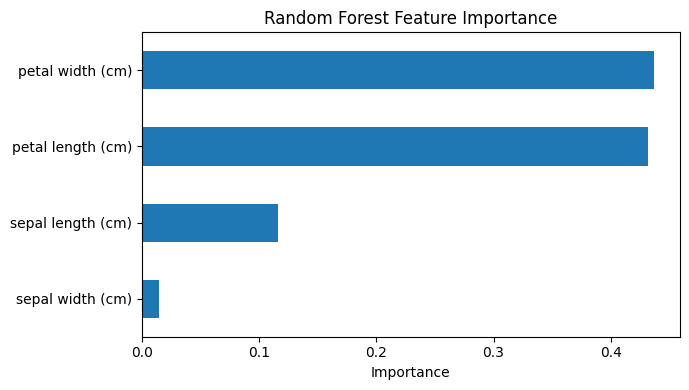

,importance
petal width (cm),0.437185
petal length (cm),0.431466
sepal length (cm),0.116349
sepal width (cm),0.015000


In [8]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values()

importance.plot(kind="barh", figsize=(7, 4))
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(importance.sort_values(ascending=False).to_frame("importance"))

## 9. Predict a new flower

The example below uses four measurements in the same order as the dataset's feature columns.

In [9]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)
prediction = model.predict(new_flower)[0]
print("Predicted species:", iris.target_names[prediction])

Predicted species: setosa


## 10. Conclusion

In this notebook, we loaded and explored the Iris dataset, trained a Random Forest classifier, and evaluated it on held-out samples. The confusion matrix shows the types of correct and incorrect predictions, while feature importance describes which measurements the fitted model relied on most.

### Possible next steps
- Compare Random Forest with Logistic Regression and a Decision Tree.
- Use cross-validation to assess performance more robustly.
- Tune model hyperparameters and compare results.

**Note:** Run all cells from top to bottom to generate the outputs and plots for your portfolio.